In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [13]:
udf = pd.read_csv('universities.csv',index_col='Univ')
udf.head()

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
Univ,,,,,,
Brown,1310,89,22,13,22704,94
CalTech,1415,100,25,6,63575,81
CMU,1260,62,59,9,25026,72
Columbia,1310,76,24,12,31510,88
Cornell,1280,83,33,13,21864,90


In [14]:
from sklearn.preprocessing import StandardScaler

In [15]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(udf)

In [16]:
scaled_data

array([[ 0.41028362,  0.6575195 , -0.88986682,  0.07026045, -0.33141256,
         0.82030265],
       [ 1.39925928,  1.23521235, -0.73465749, -1.68625071,  2.56038138,
        -0.64452351],
       [-0.06065717, -0.76045386,  1.02438157, -0.93346022, -0.16712136,
        -1.65863393],
       [ 0.41028362, -0.02520842, -0.78639393, -0.18066972,  0.29164871,
         0.14422904],
       [ 0.12771914,  0.34241431, -0.32076595,  0.07026045, -0.39084607,
         0.36958691],
       [ 0.69284809,  0.6575195 , -0.83813038, -0.68253005,  0.33778044,
         0.93298158],
       [ 0.4573777 ,  0.71003703, -0.47597528, -0.18066972,  0.29695528,
         0.93298158],
       [-0.10775125, -0.13024348, -0.78639393, -0.18066972, -0.51381683,
         0.59494478],
       [ 1.25797704,  0.76255456, -1.30375836, -0.43159988,  0.85874344,
         1.15833946],
       [ 0.36318954, -0.07772595,  0.24833493, -1.43532055,  2.21481798,
         0.0315501 ],
       [ 1.06960072,  0.92010716, -0.47597528, -0.

In [17]:
from sklearn.preprocessing import MinMaxScaler

In [18]:
mscaler = MinMaxScaler()
mscaler.fit_transform(udf)

array([[0.74390244, 0.84722222, 0.10526316, 0.36842105, 0.25514388,
        0.9       ],
       [1.        , 1.        , 0.14473684, 0.        , 1.        ,
        0.46666667],
       [0.62195122, 0.47222222, 0.59210526, 0.15789474, 0.29746132,
        0.16666667],
       [0.74390244, 0.66666667, 0.13157895, 0.31578947, 0.41562939,
        0.7       ],
       [0.67073171, 0.76388889, 0.25      , 0.36842105, 0.23983525,
        0.76666667],
       [0.81707317, 0.84722222, 0.11842105, 0.21052632, 0.4275118 ,
        0.93333333],
       [0.75609756, 0.86111111, 0.21052632, 0.31578947, 0.41699623,
        0.93333333],
       [0.6097561 , 0.63888889, 0.13157895, 0.31578947, 0.20816096,
        0.83333333],
       [0.96341463, 0.875     , 0.        , 0.26315789, 0.56169926,
        1.        ],
       [0.73170732, 0.65277778, 0.39473684, 0.05263158, 0.91099123,
        0.66666667],
       [0.91463415, 0.91666667, 0.21052632, 0.21052632, 0.47686392,
        0.8       ],
       [0.62195122, 0

In [19]:
from sklearn.cluster import KMeans

In [20]:
model = KMeans(n_clusters=3, random_state=42)
model.fit(scaled_data)

KMeans(n_clusters=3, random_state=42)

In [21]:
model.labels_

array([2, 0, 1, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2,
       2, 1, 2], dtype=int32)

In [22]:
udf['label']=model.labels_

In [23]:
udf

,SAT,Top10,Accept,SFRatio,Expenses,GradRate,label
Univ,,,,,,,
Brown,1310,89,22,13,22704,94,2
CalTech,1415,100,25,6,63575,81,0
CMU,1260,62,59,9,25026,72,1
Columbia,1310,76,24,12,31510,88,2
Cornell,1280,83,33,13,21864,90,2
Dartmouth,1340,89,23,10,32162,95,2
Duke,1315,90,30,12,31585,95,2
Georgetown,1255,74,24,12,20126,92,2
Harvard,1400,91,14,11,39525,97,2


In [24]:
grp = udf.groupby('label')

In [26]:
for x,y in grp:
    print(y)
    print('_'*60)

               SAT  Top10  Accept  SFRatio  Expenses  GradRate  label
Univ                                                                 
CalTech       1415    100      25        6     63575        81      0
JohnsHopkins  1305     75      44        7     58691        87      0
____________________________________________________________
             SAT  Top10  Accept  SFRatio  Expenses  GradRate  label
Univ                                                               
CMU         1260     62      59        9     25026        72      1
PennState   1081     38      54       18     10185        80      1
Purdue      1005     28      90       19      9066        69      1
TexasA&M    1075     49      67       25      8704        67      1
UMichigan   1180     65      68       16     15470        85      1
UWisconsin  1085     40      69       15     11857        71      1
____________________________________________________________
               SAT  Top10  Accept  SFRatio  Expenses  

In [28]:
grp.agg('mean')

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
label,,,,,,
0,1360.000000,87.500000,34.500000,6.500000,61133.000000,84.000000
1,1114.333333,47.000000,67.833333,17.000000,13384.666667,74.000000
2,1309.117647,85.588235,29.647059,11.941176,28360.352941,91.529412


In [30]:
model.inertia_

49.68561485626175

In [31]:
wcss = []

for i in range(1,11):
    model = KMeans(n_clusters=i)
    model.fit(scaled_data)
    wcss.append(model.inertia_)

In [32]:
wcss

[150.0,
 64.1452839501027,
 45.07934922478072,
 34.79612750585774,
 32.40901765509347,
 23.177557440561095,
 21.52158898714137,
 18.309080642610525,
 15.06281564936253,
 11.065746501380486]

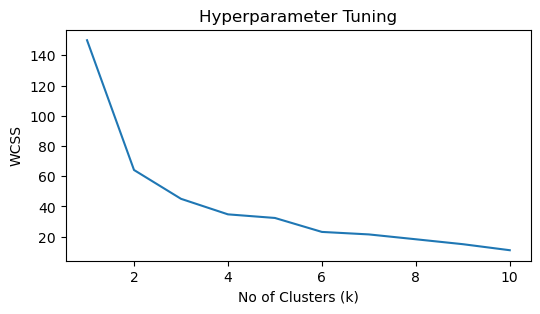

In [33]:
plt.figure(figsize=(6,3))
plt.title('Hyperparameter Tuning')
plt.xlabel('No of Clusters (k)')
plt.ylabel('WCSS')
plt.plot(range(1,11),wcss)
plt.show()